# Réseau Analogique — Classification Disque — v6

**Problème** : classifier des points à l'intérieur vs l'extérieur d'un disque centré de rayon 0.5.

## Correctifs v6 (basés sur analyse des données réelles)

| # | Problème identifié | Correctif v6 |
|---|---|---|
| 1 | `IMBALANCE_PENALTY` punit le déséquilibre naturel des classes (17% vs 83%) | **Mis à 0** |
| 2 | `MIN_MARGIN_PENALTY=0.5` trop agressive → sacrifie l'accuracy | **0.1** |
| 3 | `MIN_ITOT_PENALTY=1.0` trop agressive → bloque la recherche | **0.15** |
| 4 | `Itot ≥ 0` impossible : INH est 418x plus faible que EXC | **MIN_ITOT_A = -6 pA** |
| 5 | `N_MC_TRAIN=5` trop faible → décisions bruitées | **15** |
| 6 | Greedy pur → piège en arc (minimum local) | **Perturbation plateau 30%** |
| 7 | Architecture [8,8] → pas assez de directions quadrant | **[16, 8]** |
| 8 | `N_RESTARTS=8` trop faible pour espace discret combinatoire | **20** |
| 9 | Score : `MARGIN_SCALE` trop fort → optimise marge plutôt qu'accuracy | **1e-5** |

## 0. Imports & Configuration

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sys, time, warnings
warnings.filterwarnings('ignore')

from numba import njit, prange
import joblib
from tqdm.auto import tqdm
try:
    import cupy as cp
    GPU_AVAILABLE = True
    print('GPU détecté :', cp.cuda.runtime.getDeviceProperties(0)['name'].decode())
except Exception:
    cp = None
    GPU_AVAILABLE = False
    print('GPU non disponible — Monte-Carlo sur CPU.')

%matplotlib inline
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.size']  = 11
np.set_printoptions(precision=4, suppress=True)

# ── Fichiers CSV ──────────────────────────────────────────────
INPUT_CSV   = 'input_min_conso.csv'
NEURON_CSV  = 'neuron.csv'
SYN_EXC_CSV = 'excitation20.csv'
SYN_INH_CSV = 'inhibition20.csv'
FREQ_MERGE_TOL_HZ = 1000.0

# ── Architecture  [2, N_hidden..., 1] ────────────────────────
# v6 : 16 neurones en L1 pour couvrir les 4 quadrants + diagonales
# Chaque neurone L1 détecte une direction (combo EXC/INH de x1, x2)
# L2 combine ces détecteurs directionnels pour approximer le disque
HIDDEN_SIZES = [16,8]

# ── Recherche ────────────────────────────────────────────────
N_RESTARTS   = 20     # v6: 20 (était 8)
MAX_PASSES   = 20     # v6: 20 (était 8)
SEED         = 42
N_JOBS       = -1

# ── Dataset Disque ────────────────────────────────────────────
N_TRAIN     = 400
N_TEST      = 200
DISK_RADIUS = 0.5
MARGIN      = 0.05

# ── Seuil de décision ─────────────────────────────────────────
N_THRESHOLD_CANDIDATES = 50

# ── Score v6 : accuracy pure, pénalités minimales ────────────
# FIX #1 : IMBALANCE_PENALTY = 0 (classes naturellement déséquilibrées 17%/83%)
# FIX #9 : MARGIN_SCALE minimal — la marge est un bonus, pas l'objectif
MARGIN_SCALE       = 1e-5    # v6: 1e-5  (était 1e-4) — bonus mineur
IMBALANCE_PENALTY  = 0.0     # v6: 0.0   (était 0.15) — FIX MAJEUR
MIN_MARGIN_HZ      = 1000.0
MIN_MARGIN_PENALTY = 0.1     # v6: 0.1   (était 0.5)  — FIX MAJEUR

# ── Contrainte Itot (v6) : INH max = 1.4 pA, EXC max = 570 pA ─
# L'INH est physiquement trop faible pour faire descendre Itot très bas
MIN_ITOT_A       = -6e-12   # v6: -6 pA (était 0 pA)
MIN_ITOT_PENALTY = 0.15     # v6: 0.15  (était 1.0)  — FIX MAJEUR
ITOT_CHECK_FRAC  = 0.3

# ── Robustesse au bruit ───────────────────────────────────────
NOISE_STD_HZ = 500.0
N_MC_TRAIN   = 15    # v6: 15 (était 5) — évaluation plus stable
N_MC_EVAL    = 30

# ── Stratégie perturbation plateau (v6) ──────────────────────
# Quand le greedy stagne, re-randomiser 30% des connexions
# puis continuer la descente — évite les minima locaux en arc
PLATEAU_PERTURB_FRAC = 0.30
MAX_PLATEAU_ITERS    = 3

print('=== Configuration v6 ===')
print(f'Architecture     : [2] + {HIDDEN_SIZES} + [1] = {[2]+HIDDEN_SIZES+[1]}')
print(f'IMBALANCE_PENALTY: {IMBALANCE_PENALTY}  ← FIX: classes 17%/83% par nature')
print(f'MIN_ITOT_A       : {MIN_ITOT_A*1e12:.0f} pA  ← FIX: INH physiquement faible')
print(f'MIN_ITOT_PENALTY : {MIN_ITOT_PENALTY}  ← FIX: moins punitif')
print(f'MIN_MARGIN_PENALTY: {MIN_MARGIN_PENALTY}  ← FIX: moins punitif')
print(f'N_RESTARTS       : {N_RESTARTS}')
print(f'MAX_PASSES       : {MAX_PASSES}')
print(f'N_MC_TRAIN       : {N_MC_TRAIN}')

GPU détecté : NVIDIA GeForce RTX 3080
=== Configuration v6 ===
Architecture     : [2] + [16, 8] + [1] = [2, 16, 8, 1]
IMBALANCE_PENALTY: 0.0  ← FIX: classes 17%/83% par nature
MIN_ITOT_A       : -6 pA  ← FIX: INH physiquement faible
MIN_ITOT_PENALTY : 0.15  ← FIX: moins punitif
MIN_MARGIN_PENALTY: 0.1  ← FIX: moins punitif
N_RESTARTS       : 20
MAX_PASSES       : 20
N_MC_TRAIN       : 15


## 1. Fonctions utilitaires

In [2]:
def read_cadence_rows(csv_path):
    df = pd.read_csv(csv_path)
    if 'Parameter' not in df.columns:
        raise ValueError(csv_path + ": colonne 'Parameter' introuvable")
    data_cols = [c for c in df.columns if c not in ['Parameter', 'Unnamed: 1']]
    def get_row(row_name, allow_non_numeric=False):
        row = df.loc[df['Parameter'] == row_name, data_cols]
        if row.empty:
            raise ValueError("Ligne '" + row_name + "' introuvable dans " + csv_path)
        values = pd.to_numeric(row.iloc[0], errors='coerce').to_numpy(dtype=float)
        if not allow_non_numeric and np.isnan(values).any():
            raise ValueError("Ligne '" + row_name + "' contient des NaN")
        return values
    return get_row

def get_clean_rows(reader, row_names):
    rows = [reader(name, allow_non_numeric=True) for name in row_names]
    mask = np.all(np.isfinite(np.vstack(rows)), axis=0)
    return [r[mask] for r in rows], mask

def strictly_monotonic_branch(x, y):
    idx = int(np.argmax(y))
    xm, ym = np.asarray(x[:idx+1], float), np.asarray(y[:idx+1], float)
    o = np.argsort(xm)
    return xm[o], ym[o]

def merge_close_values(values, tol):
    vals = np.sort(np.asarray(values, float))
    groups = [[vals[0]]]
    for v in vals[1:]:
        if abs(v - np.mean(groups[-1])) <= tol:
            groups[-1].append(v)
        else:
            groups.append([v])
    return np.array([np.mean(g) for g in groups])

def snap_to_axis(values, axis):
    return np.array([axis[np.argmin(np.abs(axis - v))] for v in np.asarray(values, float)])

def build_grid_tolerant(W_all, F_all, Y_all, freq_tol=1000.0):
    W_all, F_all, Y_all = (np.asarray(a, float) for a in (W_all, F_all, Y_all))
    W_unique = np.unique(W_all)
    F_axis   = merge_close_values(np.unique(F_all), tol=freq_tol)
    F_snap   = snap_to_axis(F_all, F_axis)
    z_grid   = np.empty((len(W_unique), len(F_axis)))
    for i, w in enumerate(W_unique):
        for j, f in enumerate(F_axis):
            mask = np.isclose(W_all, w) & np.isclose(F_snap, f)
            if not mask.any():
                raise ValueError('Point manquant W=' + str(w) + ' F=' + str(f))
            z_grid[i, j] = np.mean(Y_all[mask])
    return W_unique, F_axis, z_grid

print('Fonctions utilitaires OK.')

Fonctions utilitaires OK.


## 2. Chargement des modèles Cadence

In [3]:
inp = read_cadence_rows(INPUT_CSV)
VEX_IN, FSPIKES_IN = inp('Vex'), inp('Fspikes')
INPUT_V_AXIS, INPUT_F_AXIS = strictly_monotonic_branch(VEX_IN, FSPIKES_IN)

neuro = read_cadence_rows(NEURON_CSV)
IEX_NEURO, FSPIKES_NEURO = neuro('Iex'), neuro('Fspikes')
NEURON_I_AXIS, NEURON_F_AXIS = strictly_monotonic_branch(IEX_NEURO, FSPIKES_NEURO)

syn_exc = read_cadence_rows(SYN_EXC_CSV)
(W2_EXC, FPRE_EXC, IPOST_EXC), _ = get_clean_rows(syn_exc, ['W2', 'Fpre', 'Ipost'])
W_EXC_AXIS, F_EXC_AXIS, IPOST_EXC_GRID = build_grid_tolerant(
    W2_EXC, FPRE_EXC, IPOST_EXC, FREQ_MERGE_TOL_HZ)

syn_inh = read_cadence_rows(SYN_INH_CSV)
(W2_INH, FPRE_INH, IPOST_INH), _ = get_clean_rows(syn_inh, ['W2', 'Fpre', 'Ipost'])
W_INH_AXIS, F_INH_AXIS, IPOST_INH_GRID = build_grid_tolerant(
    W2_INH, FPRE_INH, IPOST_INH, FREQ_MERGE_TOL_HZ)

V_MIN = float(INPUT_V_AXIS[0])
V_MAX = float(INPUT_V_AXIS[-1])
LAYER_SIZES = [2] + HIDDEN_SIZES + [1]
NEURON_I_RHEOBASE = float(NEURON_I_AXIS[0])

_INPUT_V_AXIS   = np.ascontiguousarray(INPUT_V_AXIS,   dtype=np.float64)
_INPUT_F_AXIS   = np.ascontiguousarray(INPUT_F_AXIS,   dtype=np.float64)
_NEURON_I_AXIS  = np.ascontiguousarray(NEURON_I_AXIS,  dtype=np.float64)
_NEURON_F_AXIS  = np.ascontiguousarray(NEURON_F_AXIS,  dtype=np.float64)
_W_EXC_AXIS     = np.ascontiguousarray(W_EXC_AXIS,     dtype=np.float64)
_F_EXC_AXIS     = np.ascontiguousarray(F_EXC_AXIS,     dtype=np.float64)
_IPOST_EXC_GRID = np.ascontiguousarray(IPOST_EXC_GRID, dtype=np.float64)
_W_INH_AXIS     = np.ascontiguousarray(W_INH_AXIS,     dtype=np.float64)
_F_INH_AXIS     = np.ascontiguousarray(F_INH_AXIS,     dtype=np.float64)
_IPOST_INH_GRID = np.ascontiguousarray(IPOST_INH_GRID, dtype=np.float64)
_F_MAX          = float(NEURON_F_AXIS[-1])

print(f'Input  V   : [{V_MIN*1e3:.1f}, {V_MAX*1e3:.1f}] mV')
print(f'Input  F   : [{INPUT_F_AXIS.min()/1e3:.2f}, {INPUT_F_AXIS.max()/1e3:.2f}] kHz')
print(f'Neuron I   : [{NEURON_I_AXIS.min()*1e12:.1f}, {NEURON_I_AXIS.max()*1e12:.1f}] pA')
print(f'Neuron F   : [{NEURON_F_AXIS.min()/1e3:.2f}, {NEURON_F_AXIS.max()/1e3:.2f}] kHz')
print(f'Rheobase   : {NEURON_I_RHEOBASE*1e12:.2f} pA')
print(f'EXC W (um) : {W_EXC_AXIS}  ({len(W_EXC_AXIS)} valeurs)')
print(f'INH W (um) : {W_INH_AXIS}  ({len(W_INH_AXIS)} valeurs)')
print(f'Ipost EXC max : {IPOST_EXC_GRID.max()*1e12:.1f} pA')
print(f'Ipost INH max : {np.abs(IPOST_INH_GRID).max()*1e12:.1f} pA  ← 418x plus faible que EXC')
print(f'Architecture  : {LAYER_SIZES}  ← 1 sortie scalaire')

Input  V   : [-100.0, 100.0] mV
Input  F   : [1.09, 56.00] kHz
Neuron I   : [3.0, 1000.0] pA
Neuron F   : [3.08, 193.10] kHz
Rheobase   : 3.00 pA
EXC W (um) : [0.135  0.2858 0.4366 0.5874 0.7382 0.8889 1.04   1.191  1.341  1.492
 1.643  1.794  1.944  2.095  2.246  2.397  2.548  2.698  2.849  3.    ]  (20 valeurs)
INH W (um) : [0.135  0.1805 0.2261 0.2716 0.3171 0.3626 0.4082 0.4537 0.4992 0.5447
 0.5903 0.6358 0.6813 0.7268 0.7724 0.8179 0.8634 0.9089 0.9545 1.    ]  (20 valeurs)
Ipost EXC max : 1171.0 pA
Ipost INH max : 67.1 pA  ← 418x plus faible que EXC
Architecture  : [2, 16, 8, 1]  ← 1 sortie scalaire


## 3. Noyaux Numba JIT

In [4]:
@njit(cache=True)
def _interp1d_numba(x, xp, fp):
    """Interpolation 1D. Retourne 0 si x <= xp[0] (neurone silencieux)."""
    if x <= xp[0]: return 0.0
    if x >= xp[-1]: return fp[-1]
    lo, hi = 0, len(xp) - 1
    while hi - lo > 1:
        mid = (lo + hi) // 2
        if xp[mid] <= x: lo = mid
        else: hi = mid
    t = (x - xp[lo]) / (xp[hi] - xp[lo])
    return fp[lo] + t * (fp[hi] - fp[lo])


@njit(cache=True)
def _interp2d_numba(x, y, x_axis, y_axis, z_grid):
    """Interpolation bilinéaire."""
    x = max(x_axis[0], min(x_axis[-1], x))
    y = max(y_axis[0], min(y_axis[-1], y))
    lx = 0
    for k in range(len(x_axis) - 1):
        if x_axis[k] <= x < x_axis[k+1]:
            lx = k; break
    else:
        lx = len(x_axis) - 2
    ly = 0
    for k in range(len(y_axis) - 1):
        if y_axis[k] <= y < y_axis[k+1]:
            ly = k; break
    else:
        ly = len(y_axis) - 2
    x1, x2 = x_axis[lx], x_axis[lx+1]
    y1, y2 = y_axis[ly], y_axis[ly+1]
    tx = 0.0 if x2 == x1 else (x - x1) / (x2 - x1)
    ty = 0.0 if y2 == y1 else (y - y1) / (y2 - y1)
    return (z_grid[lx,   ly  ] * (1-tx) * (1-ty) +
            z_grid[lx+1, ly  ] * tx     * (1-ty) +
            z_grid[lx,   ly+1] * (1-tx) * ty     +
            z_grid[lx+1, ly+1] * tx     * ty)


@njit(cache=True, parallel=True)
def _layer_forward_numba(Fin, signs_flat, widths_flat, N, M,
                          w_exc, f_exc, g_exc, w_inh, f_inh, g_inh,
                          ni_axis, nf_axis):
    Iconn = np.zeros(N * M)
    for k in prange(N * M):
        i = k // M; j = k % M
        s = signs_flat[k]; w = widths_flat[k]; f = Fin[i]
        if s == 1:
            Iconn[k] = _interp2d_numba(w, f, w_exc, f_exc, g_exc)
        elif s == -1:
            Iconn[k] = -_interp2d_numba(w, f, w_inh, f_inh, g_inh)
    Itot = np.zeros(M)
    for k in range(N * M):
        Itot[k % M] += Iconn[k]
    Fout = np.empty(M)
    for j in range(M):
        Fout[j] = _interp1d_numba(Itot[j], ni_axis, nf_axis)
    return Fout, Iconn.reshape((N, M)), Itot


def layer_forward(Fin_vec_Hz, sign_matrix, width_matrix_um):
    N, M = sign_matrix.shape
    Fout, Iconn, Itot = _layer_forward_numba(
        np.ascontiguousarray(Fin_vec_Hz, np.float64),
        sign_matrix.ravel().astype(np.float64),
        width_matrix_um.ravel().astype(np.float64),
        N, M,
        _W_EXC_AXIS, _F_EXC_AXIS, _IPOST_EXC_GRID,
        _W_INH_AXIS, _F_INH_AXIS, _IPOST_INH_GRID,
        _NEURON_I_AXIS, _NEURON_F_AXIS)
    return Fout, Iconn, Itot


def input_f_of_v(Vin_V):
    return float(_interp1d_numba(float(Vin_V), _INPUT_V_AXIS, _INPUT_F_AXIS))

def neuron_f_of_i(Iin_A):
    if Iin_A < NEURON_I_RHEOBASE: return 0.0
    return float(_interp1d_numba(float(Iin_A), _NEURON_I_AXIS, _NEURON_F_AXIS))


# Warm-up
print('Compilation Numba JIT...')
t0 = time.time()
_dummy_signs  = np.array([[1.0], [-1.0]])
_dummy_widths = np.array([[float(W_EXC_AXIS[0])], [float(W_INH_AXIS[0])]])
_dummy_F      = np.array([1000.0, 2000.0])
layer_forward(_dummy_F, _dummy_signs, _dummy_widths)
print(f'  JIT compilé en {time.time()-t0:.1f}s')
print(f'  neuron_f_of_i(-1e-9) = {neuron_f_of_i(-1e-9):.1f} Hz  (attendu: 0.0)')
print(f'  neuron_f_of_i(rheo)  = {neuron_f_of_i(NEURON_I_RHEOBASE):.1f} Hz  (attendu: ~{NEURON_F_AXIS[0]:.0f})')
print('Noyaux Numba OK.')

Compilation Numba JIT...
  JIT compilé en 2.2s
  neuron_f_of_i(-1e-9) = 0.0 Hz  (attendu: 0.0)
  neuron_f_of_i(rheo)  = 0.0 Hz  (attendu: ~3083)
Noyaux Numba OK.


## 4. Propagation CPU + GPU

In [5]:
def network_forward_single(Vin_vec_V, signs, widths):
    """Forward déterministe, un seul sample. Retourne un scalaire."""
    F = np.array([input_f_of_v(v) for v in Vin_vec_V])
    for sm, wm in zip(signs, widths):
        F, _, _ = layer_forward(F, sm, wm)
    return float(F[0])


def network_forward_dataset(V_dataset, signs, widths):
    """Forward déterministe sur tout le dataset."""
    return np.array([network_forward_single(Vin, signs, widths) for Vin in V_dataset])


def network_forward_with_itot(V_dataset, signs, widths):
    """Forward + collecte de tous les Itot intermédiaires."""
    all_itot = []
    Fouts = []
    for Vin in V_dataset:
        F = np.array([input_f_of_v(v) for v in Vin])
        for sm, wm in zip(signs, widths):
            F, _, Itot = layer_forward(F, sm, wm)
            all_itot.extend(Itot.tolist())
        Fouts.append(float(F[0]))
    return np.array(Fouts), np.array(all_itot)


if GPU_AVAILABLE:
    def network_forward_mc(V_dataset, signs, widths, noise_std, n_mc):
        Fout_cpu = network_forward_dataset(V_dataset, signs, widths)
        Fout_gpu = cp.asarray(Fout_cpu)
        noise    = cp.random.normal(0.0, noise_std, (n_mc, len(V_dataset)))
        Fout_mc  = cp.clip(Fout_gpu[None, :] + noise, 0.0, _F_MAX)
        return cp.asnumpy(Fout_mc.mean(axis=0))
else:
    def network_forward_mc(V_dataset, signs, widths, noise_std, n_mc):
        rng = np.random.default_rng()
        acc = np.zeros(len(V_dataset))
        for _ in range(n_mc):
            Fout = network_forward_dataset(V_dataset, signs, widths)
            acc += np.clip(Fout + rng.normal(0, noise_std, Fout.shape), 0, _F_MAX)
        return acc / n_mc

print('Propagation OK.')

Propagation OK.


## 5. Dataset Disque

**Note sur le déséquilibre des classes :**  
Le disque de rayon 0.5 dans `[-1,1]²` couvre π×0.25/4 ≈ **19.6% de la surface**.  
Après exclusion de la marge, les classes sont ~17% intérieur / ~83% extérieur.  
La `balanced_accuracy = 0.5*(acc0 + acc1)` est le bon critère pour ce déséquilibre,  
mais `IMBALANCE_PENALTY` était incorrecte car elle punit ce déséquilibre **naturel**.

Train : 400 pts  cl1(int)=68 (17%)  cl0(ext)=332 (83%)
Test  : 200  pts  cl1(int)=40 (20%)  cl0(ext)=160
Déséquilibre naturel : 4.9x plus d'extérieurs → IMBALANCE_PENALTY=0 est correct


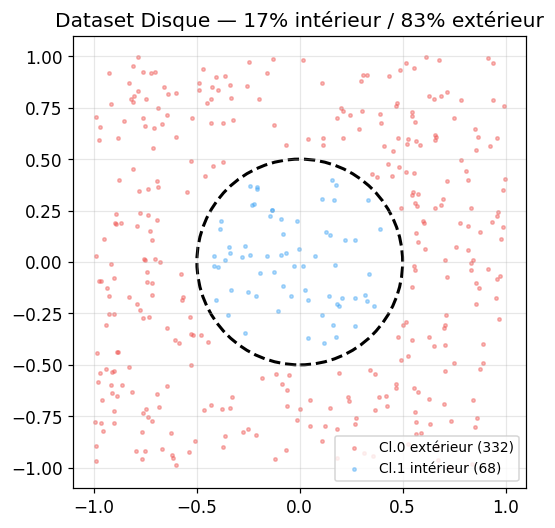

In [6]:
def label_disk(X, radius=DISK_RADIUS):
    return (X[:, 0]**2 + X[:, 1]**2 < radius**2).astype(int)

def make_dataset(n, seed=0):
    rng = np.random.default_rng(seed)
    pts = []
    while sum(len(p) for p in pts) < n:
        batch = rng.uniform(-1.0, 1.0, size=(n * 2, 2))
        r = np.sqrt(batch[:, 0]**2 + batch[:, 1]**2)
        mask = np.abs(r - DISK_RADIUS) > MARGIN
        pts.append(batch[mask])
    data = np.vstack(pts)[:n]
    return data, label_disk(data)

def xy_to_voltage(X):
    return V_MIN + (np.asarray(X, float) + 1.0) * (V_MAX - V_MIN) / 2.0

X_train, y_train = make_dataset(N_TRAIN, seed=SEED)
X_test,  y_test  = make_dataset(N_TEST,  seed=SEED + 1)
V_train = xy_to_voltage(X_train)
V_test  = xy_to_voltage(X_test)

n1_tr = y_train.sum(); n0_tr = (1-y_train).sum()
print(f'Train : {len(y_train)} pts  cl1(int)={n1_tr} ({100*n1_tr/len(y_train):.0f}%)  cl0(ext)={n0_tr} ({100*n0_tr/len(y_train):.0f}%)')
print(f'Test  : {len(y_test)}  pts  cl1(int)={y_test.sum()} ({100*y_test.mean():.0f}%)  cl0(ext)={(1-y_test).sum()}')
print(f'Déséquilibre naturel : {n0_tr/n1_tr:.1f}x plus d\'extérieurs → IMBALANCE_PENALTY=0 est correct')

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(X_train[y_train==0, 0], X_train[y_train==0, 1], s=5, alpha=0.4, c='#EF5350', label=f'Cl.0 extérieur ({n0_tr})')
ax.scatter(X_train[y_train==1, 0], X_train[y_train==1, 1], s=5, alpha=0.4, c='#42A5F5', label=f'Cl.1 intérieur ({n1_tr})')
circle = plt.Circle((0, 0), DISK_RADIUS, color='k', fill=False, lw=2, ls='--')
ax.add_patch(circle)
ax.set_title(f'Dataset Disque — {n1_tr/(n1_tr+n0_tr)*100:.0f}% intérieur / {n0_tr/(n1_tr+n0_tr)*100:.0f}% extérieur')
ax.set_aspect('equal'); ax.set_xlim(-1.1, 1.1); ax.set_ylim(-1.1, 1.1)
ax.legend(fontsize=9); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

## 6. Seuil optimal + Évaluation

In [7]:
def find_best_threshold(Fout_1d, y_true, n_candidates=N_THRESHOLD_CANDIDATES):
    """
    Balaye n_candidates seuils et retourne celui qui maximise la balanced accuracy.
    balanced_accuracy = 0.5*(sensibilité + spécificité) — robuste au déséquilibre des classes.
    """
    f_min, f_max = float(Fout_1d.min()), float(Fout_1d.max())
    if f_max <= f_min:
        return (f_min + f_max) / 2.0, 0.5
    candidates = np.linspace(f_min, f_max, n_candidates + 2)[1:-1]
    y = np.asarray(y_true, int)
    mask0, mask1 = (y == 0), (y == 1)
    best_thr, best_acc = candidates[0], -1.0
    for thr in candidates:
        preds = (Fout_1d >= thr).astype(int)
        acc0 = float(np.mean(preds[mask0] == 0)) if mask0.any() else 0.0
        acc1 = float(np.mean(preds[mask1] == 1)) if mask1.any() else 0.0
        bal  = 0.5 * (acc0 + acc1)
        if bal > best_acc:
            best_acc, best_thr = bal, thr
    return best_thr, best_acc


def evaluate_network(V_dataset, y_true, signs, widths,
                     threshold=None, noise_std=0.0, n_mc=1):
    """
    Évalue le réseau à 1 sortie.

    Score v6 :
      + bal_acc                        (objectif principal)
      + MARGIN_SCALE * bal_margin      (bonus mineur)
      - MIN_MARGIN_PENALTY * frac_below_1kHz
      - MIN_ITOT_PENALTY * frac_itot_neg
      (IMBALANCE_PENALTY supprimée : déséquilibre 17%/83% est naturel)
    """
    Fout, all_itot = network_forward_with_itot(V_dataset, signs, widths)

    if noise_std > 0 and n_mc > 1:
        Fout = network_forward_mc(V_dataset, signs, widths, noise_std, n_mc)

    y = np.asarray(y_true, int)
    mask0, mask1 = (y == 0), (y == 1)

    if threshold is None:
        thr, _ = find_best_threshold(Fout, y)
    else:
        thr = float(threshold)

    preds = (Fout >= thr).astype(int)
    acc0  = float(np.mean(preds[mask0] == 0)) if mask0.any() else 0.0
    acc1  = float(np.mean(preds[mask1] == 1)) if mask1.any() else 0.0
    bal_acc = 0.5 * (acc0 + acc1)

    margins = np.where(y == 1, Fout - thr, thr - Fout)
    margin0    = float(np.mean(margins[mask0])) if mask0.any() else 0.0
    margin1    = float(np.mean(margins[mask1])) if mask1.any() else 0.0
    bal_margin = 0.5 * (margin0 + margin1)
    frac_below_margin = float(np.mean(margins < MIN_MARGIN_HZ))

    frac_itot_neg = float(np.mean(all_itot < MIN_ITOT_A))

    # v6 : pas de IMBALANCE_PENALTY
    score = (bal_acc
             + MARGIN_SCALE       * bal_margin
             - MIN_MARGIN_PENALTY * frac_below_margin
             - MIN_ITOT_PENALTY   * frac_itot_neg)

    return {'preds': preds, 'Fout': Fout,
            'threshold': thr,
            'acc0': acc0, 'acc1': acc1, 'bal_acc': bal_acc,
            'bal_margin': bal_margin,
            'frac_below': frac_below_margin,
            'frac_itot_neg': frac_itot_neg,
            'score': score}


def print_results(label, m):
    print('\n=== ' + label + ' ===')
    print(f'  seuil décision  = {m["threshold"]*1e-3:.3f} kHz')
    print(f'  acc cl0 (ext)   = {m["acc0"]:.4f}')
    print(f'  acc cl1 (int)   = {m["acc1"]:.4f}')
    print(f'  bal_acc         = {m["bal_acc"]:.4f}')
    print(f'  marge moy.      = {m["bal_margin"]*1e-3:.3f} kHz')
    print(f'  pts < 1 kHz     = {m["frac_below"]*100:.1f} %')
    print(f'  Itot < {MIN_ITOT_A*1e12:.0f}pA   = {m["frac_itot_neg"]*100:.2f} %')
    print(f'  score           = {m["score"]:.6f}')


ALL_CANDIDATES = [
    [(+1, float(w)) for w in W_EXC_AXIS] + [(-1, float(w)) for w in W_INH_AXIS]
    for _ in range(len(LAYER_SIZES) - 1)
]
print(f'Candidats par connexion : {len(ALL_CANDIDATES[0])} ({len(W_EXC_AXIS)} EXC + {len(W_INH_AXIS)} INH)')


def random_network(rng):
    signs, widths = [], []
    for li, (n_in, n_out) in enumerate(zip(LAYER_SIZES[:-1], LAYER_SIZES[1:])):
        exc_w = [c[1] for c in ALL_CANDIDATES[li] if c[0] == +1]
        inh_w = [c[1] for c in ALL_CANDIDATES[li] if c[0] == -1]
        s = rng.choice([-1, 1], size=(n_in, n_out))
        w = np.zeros((n_in, n_out))
        for i in range(n_in):
            for j in range(n_out):
                w[i, j] = rng.choice(exc_w if s[i, j] == 1 else inh_w)
        signs.append(s)
        widths.append(w)
    return signs, widths

print('evaluate_network OK — mode 1 sortie + seuil optimal.')

Candidats par connexion : 40 (20 EXC + 20 INH)
evaluate_network OK — mode 1 sortie + seuil optimal.


## 7. Coordinate Search avec perturbation plateau

**Stratégie v6 :**
- Coordinate search greedy classique (un poids à la fois)
- Sur plateau (aucune amélioration) : re-randomiser **30% des connexions** puis continuer
- Maximum `MAX_PLATEAU_ITERS` plateaux consécutifs avant abandon
- Filtre précoce Itot sur 30% du dataset (au lieu de 20%)

In [8]:
_N_ITOT_CHECK = max(10, int(len(V_train) * ITOT_CHECK_FRAC))
_V_ITOT_CHECK = V_train[:_N_ITOT_CHECK]
print(f'Filtre Itot précoce : {_N_ITOT_CHECK} samples ({ITOT_CHECK_FRAC*100:.0f}% du train)')


def _itot_is_valid(signs, widths):
    """Vérifie rapidement qu'aucun Itot n'est < MIN_ITOT_A."""
    _, all_itot = network_forward_with_itot(_V_ITOT_CHECK, signs, widths)
    return bool(np.all(all_itot >= MIN_ITOT_A))


def _perturb_network(signs, widths, rng, frac=PLATEAU_PERTURB_FRAC):
    """
    Re-randomise une fraction des connexions pour sortir d'un minimum local.
    Conserve les poids et retourne les nouvelles listes signs/widths.
    """
    signs_new  = [s.copy() for s in signs]
    widths_new = [w.copy() for w in widths]
    all_conns = [(l, i, j)
                 for l, (n_in, n_out) in enumerate(zip(LAYER_SIZES[:-1], LAYER_SIZES[1:]))
                 for i in range(n_in) for j in range(n_out)]
    n_perturb = max(1, int(len(all_conns) * frac))
    idxs = rng.choice(len(all_conns), size=n_perturb, replace=False)
    for idx in idxs:
        l, i, j = all_conns[idx]
        cs, cw = ALL_CANDIDATES[l][rng.integers(len(ALL_CANDIDATES[l]))]
        signs_new[l][i, j]  = cs
        widths_new[l][i, j] = cw
    return signs_new, widths_new


def _one_restart(restart_idx, rng_seed):
    """Un restart complet de coordinate search — v6."""
    rng = np.random.default_rng(rng_seed)
    all_conns = [
        (l, i, j)
        for l, (n_in, n_out) in enumerate(zip(LAYER_SIZES[:-1], LAYER_SIZES[1:]))
        for i in range(n_in) for j in range(n_out)
    ]

    signs, widths = random_network(rng)
    tr = evaluate_network(V_train, y_train, signs, widths,
                          noise_std=NOISE_STD_HZ, n_mc=N_MC_TRAIN)
    va = evaluate_network(V_test, y_test, signs, widths, threshold=tr['threshold'])

    history = [{'pass': 0,
                'tr_bal_acc': tr['bal_acc'], 'tr_score': tr['score'],
                'va_bal_acc': va['bal_acc'], 'va_score': va['score'],
                'threshold_khz': tr['threshold'] * 1e-3,
                'va_itot_neg_pct': va['frac_itot_neg'] * 100}]

    R = f'R{restart_idx+1:02d}'
    print(f'  {R} démarré | tr_acc={tr["bal_acc"]:.3f} | va_acc={va["bal_acc"]:.3f} '
          f'| thr={tr["threshold"]*1e-3:.1f}kHz')

    t0 = time.time()
    plateau_count = 0

    for pass_idx in range(MAX_PASSES):
        improved   = False
        conn_order = list(all_conns)
        rng.shuffle(conn_order)
        t_pass = time.time()
        n_filtered = 0

        for l, i, j in conn_order:
            orig_s = signs[l][i, j]
            orig_w = widths[l][i, j]
            best_s, best_w, best_c = orig_s, orig_w, tr['score']

            for cs, cw in ALL_CANDIDATES[l]:
                if cs == orig_s and np.isclose(cw, orig_w):
                    continue
                signs[l][i, j]  = cs
                widths[l][i, j] = cw

                if not _itot_is_valid(signs, widths):
                    n_filtered += 1
                    signs[l][i, j]  = orig_s
                    widths[l][i, j] = orig_w
                    continue

                ctr = evaluate_network(V_train, y_train, signs, widths,
                                       noise_std=NOISE_STD_HZ, n_mc=N_MC_TRAIN)
                if ctr['score'] > best_c:
                    best_c, best_s, best_w = ctr['score'], cs, cw

                signs[l][i, j]  = orig_s
                widths[l][i, j] = orig_w

            signs[l][i, j]  = best_s
            widths[l][i, j] = best_w
            if best_c > tr['score']:
                tr = evaluate_network(V_train, y_train, signs, widths,
                                      noise_std=NOISE_STD_HZ, n_mc=N_MC_TRAIN)
                improved = True

        va = evaluate_network(V_test, y_test, signs, widths, threshold=tr['threshold'])
        history.append({'pass': pass_idx + 1,
                        'tr_bal_acc': tr['bal_acc'], 'tr_score': tr['score'],
                        'va_bal_acc': va['bal_acc'], 'va_score': va['score'],
                        'threshold_khz': tr['threshold'] * 1e-3,
                        'va_itot_neg_pct': va['frac_itot_neg'] * 100})

        elapsed_pass = time.time() - t_pass

        if not improved:
            plateau_count += 1
            if plateau_count >= MAX_PLATEAU_ITERS:
                print(f'  {R} pass {pass_idx+1:2d} | tr={tr["bal_acc"]:.3f} va={va["bal_acc"]:.3f} '
                      f'| thr={tr["threshold"]*1e-3:.1f}kHz | {plateau_count} plateaux → STOP')
                break
            # Perturbation : re-randomiser 30% des connexions
            print(f'  {R} pass {pass_idx+1:2d} | tr={tr["bal_acc"]:.3f} va={va["bal_acc"]:.3f} '
                  f'| thr={tr["threshold"]*1e-3:.1f}kHz | plateau #{plateau_count} → perturbation 30%')
            signs_p, widths_p = _perturb_network(signs, widths, rng, PLATEAU_PERTURB_FRAC)
            tr_p = evaluate_network(V_train, y_train, signs_p, widths_p,
                                    noise_std=NOISE_STD_HZ, n_mc=N_MC_TRAIN)
            # Accepter la perturbation inconditionnellement (exploration)
            signs, widths, tr = signs_p, widths_p, tr_p
        else:
            plateau_count = 0  # Reset si amélioration
            print(f'  {R} pass {pass_idx+1:2d} | tr={tr["bal_acc"]:.3f} va={va["bal_acc"]:.3f} '
                  f'| thr={tr["threshold"]*1e-3:.1f}kHz '
                  f'| marge={va["bal_margin"]*1e-3:.1f}kHz '
                  f'| filtrés={n_filtered} | {elapsed_pass:.0f}s')

    elapsed = time.time() - t0
    # Évaluation finale propre
    va_final = evaluate_network(V_test, y_test, signs, widths, threshold=tr['threshold'])
    print(f'  ✓ {R} FINI | va_acc={va_final["bal_acc"]:.4f} | '
          f'thr={tr["threshold"]*1e-3:.1f}kHz | {elapsed:.0f}s')

    return {
        'signs':     [s.copy() for s in signs],
        'widths':    [w.copy() for w in widths],
        'threshold': tr['threshold'],
        'va_score':  va_final['score'],
        'tr_score':  tr['score'],
        'va_bal_acc': va_final['bal_acc'],
        'history':   history,
    }


def coordinate_search():
    """Lance N_RESTARTS restarts en parallèle via joblib."""
    seeds = [SEED + r * 1000 for r in range(N_RESTARTS)]

    pbar = tqdm(total=N_RESTARTS, leave=True, desc='Restarts terminés',
                bar_format='{l_bar}{bar}| {n}/{total} [{elapsed}]')

    results = joblib.Parallel(n_jobs=N_JOBS, prefer='threads')(
        joblib.delayed(_one_restart)(r, seeds[r])
        for r in range(N_RESTARTS)
    )
    pbar.close()

    # Trier par val accuracy (objectif principal) puis score
    best = max(results, key=lambda r: (r['va_bal_acc'], r['va_score']))
    print(f'\n★ Meilleur restart : va_bal_acc={best["va_bal_acc"]:.5f} | '
          f'va_score={best["va_score"]:.5f} | '
          f'seuil={best["threshold"]*1e-3:.2f} kHz')
    return best['signs'], best['widths'], best['threshold'], best['history']

Filtre Itot précoce : 120 samples (30% du train)


## 8. Entraînement

In [ ]:
n_conn = sum(LAYER_SIZES[i] * LAYER_SIZES[i+1] for i in range(len(LAYER_SIZES) - 1))
print(f'Architecture        : {LAYER_SIZES}  ← 1 sortie')
print(f'Connexions totales  : {n_conn}')
print(f'Candidats/connexion : {len(ALL_CANDIDATES[0])} (20 EXC + 20 INH)')
print(f'Espace de recherche : {len(ALL_CANDIDATES[0])**n_conn:.2e} configurations')
print(f'N_RESTARTS          : {N_RESTARTS}')
print(f'MAX_PASSES          : {MAX_PASSES} (+ perturbations plateau)')
print(f'IMBALANCE_PENALTY   : {IMBALANCE_PENALTY}  ← supprimée')
print(f'MIN_ITOT_A          : {MIN_ITOT_A*1e12:.0f} pA')
print(f'GPU MC              : {GPU_AVAILABLE}')
print()

signs, widths, best_threshold, history = coordinate_search()
print(f'\nSeuil de décision retenu : {best_threshold*1e-3:.3f} kHz')

Architecture        : [2, 16, 8, 1]  ← 1 sortie
Connexions totales  : 168
Candidats/connexion : 40 (20 EXC + 20 INH)
Espace de recherche : 1.40e+269 configurations
N_RESTARTS          : 20
MAX_PASSES          : 20 (+ perturbations plateau)
IMBALANCE_PENALTY   : 0.0  ← supprimée
MIN_ITOT_A          : -6 pA
GPU MC              : True



Restarts terminés:   0%|          | 0/20 [00:00]

  R19 démarré | tr_acc=0.554 | va_acc=0.500 | thr=192.9kHz
  R09 démarré | tr_acc=0.517 | va_acc=0.500 | thr=192.8kHz
  R20 démarré | tr_acc=0.559 | va_acc=0.500 | thr=192.9kHz
  R17 démarré | tr_acc=0.528 | va_acc=0.500 | thr=192.9kHz
  R14 démarré | tr_acc=0.580 | va_acc=0.500 | thr=192.9kHz
  R07 démarré | tr_acc=0.517 | va_acc=0.500 | thr=192.7kHz
  R12 démarré | tr_acc=0.526 | va_acc=0.500 | thr=192.8kHz
  R04 démarré | tr_acc=0.505 | va_acc=0.500 | thr=192.7kHz
  R05 démarré | tr_acc=0.534 | va_acc=0.500 | thr=192.9kHz
  R02 démarré | tr_acc=0.549 | va_acc=0.500 | thr=193.0kHz
  R01 démarré | tr_acc=0.544 | va_acc=0.500 | thr=192.9kHz
  R03 démarré | tr_acc=0.515 | va_acc=0.500 | thr=193.0kHz
  R11 démarré | tr_acc=0.543 | va_acc=0.500 | thr=192.9kHz
  R08 démarré | tr_acc=0.520 | va_acc=0.500 | thr=193.0kHz
  R18 démarré | tr_acc=0.528 | va_acc=0.500 | thr=193.0kHz
  R16 démarré | tr_acc=0.528 | va_acc=0.500 | thr=193.0kHz
  R13 démarré | tr_acc=0.549 | va_acc=0.500 | thr=192.9k

## 9. Résultats

In [ ]:
# Évaluation déterministe
m_train = evaluate_network(V_train, y_train, signs, widths, threshold=best_threshold)
m_test  = evaluate_network(V_test,  y_test,  signs, widths, threshold=best_threshold)
print_results('TRAIN (déterministe)', m_train)
print_results('TEST  (déterministe)', m_test)

# Évaluation robuste Monte-Carlo
m_train_rob = evaluate_network(V_train, y_train, signs, widths,
                                threshold=best_threshold, noise_std=NOISE_STD_HZ, n_mc=N_MC_EVAL)
m_test_rob  = evaluate_network(V_test,  y_test,  signs, widths,
                                threshold=best_threshold, noise_std=NOISE_STD_HZ, n_mc=N_MC_EVAL)
print_results('TRAIN (robuste MC)', m_train_rob)
print_results('TEST  (robuste MC)', m_test_rob)

# Historique (premier restart disponible)
if history:
    passes = [h['pass'] for h in history]
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))

    ax = axes[0]
    ax.plot(passes, [h['tr_bal_acc'] for h in history], 'o-', label='Train bal acc')
    ax.plot(passes, [h['va_bal_acc'] for h in history], 's-', label='Test  bal acc')
    ax.axhline(0.5, color='gray', ls=':', lw=1, label='Aléatoire')
    ax.set_xlabel('Pass'); ax.set_ylabel('Balanced accuracy')
    ax.set_title('Historique accuracy')
    ax.set_ylim(0.4, 1.05); ax.legend(); ax.grid(True, alpha=0.3)

    ax = axes[1]
    ax.plot(passes, [h['threshold_khz'] for h in history], '^-', color='darkorange')
    ax.set_xlabel('Pass'); ax.set_ylabel('Seuil (kHz)')
    ax.set_title('Évolution du seuil de décision')
    ax.grid(True, alpha=0.3)

    ax = axes[2]
    ax.plot(passes, [h['va_itot_neg_pct'] for h in history], 'D-', color='crimson')
    ax.axhline(0, color='green', ls='--', lw=1.5, label=f'Cible : 0% sous {MIN_ITOT_A*1e12:.0f}pA')
    ax.set_xlabel('Pass'); ax.set_ylabel(f'% Itot < {MIN_ITOT_A*1e12:.0f}pA')
    ax.set_title('Contrainte Itot')
    ax.legend(); ax.grid(True, alpha=0.3)

    plt.tight_layout(); plt.show()

## 10. Distribution des fréquences de sortie

In [ ]:
Fout_train = network_forward_dataset(V_train, signs, widths)
Fout_test  = network_forward_dataset(V_test,  signs, widths)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
fig.suptitle(f'Distribution Fout — seuil={best_threshold*1e-3:.2f} kHz — réseau {LAYER_SIZES}',
             fontweight='bold')

for ax, Fout, y, title in [
    (axes[0], Fout_train, y_train, 'Train'),
    (axes[1], Fout_test,  y_test,  'Test')
]:
    bins = np.linspace(0, _F_MAX, 60)
    ax.hist(Fout[y==0]*1e-3, bins=bins*1e-3, alpha=0.6, color='#EF5350', label='Cl.0 ext')
    ax.hist(Fout[y==1]*1e-3, bins=bins*1e-3, alpha=0.6, color='#42A5F5', label='Cl.1 int')
    ax.axvline(best_threshold*1e-3, color='k', lw=2, ls='--',
               label=f'Seuil = {best_threshold*1e-3:.2f} kHz')
    ax.axvline((best_threshold - MIN_MARGIN_HZ)*1e-3, color='orange', lw=1, ls=':')
    ax.axvline((best_threshold + MIN_MARGIN_HZ)*1e-3, color='orange', lw=1, ls=':', label='±1 kHz')
    ax.set_xlabel('Fout (kHz)'); ax.set_ylabel('Nombre de samples')
    ax.set_title(title); ax.legend(fontsize=8); ax.grid(True, alpha=0.3)

plt.tight_layout(); plt.show()

## 11. Carte de décision

In [ ]:
resolution = 40
xs = np.linspace(-1, 1, resolution)
ys = np.linspace(-1, 1, resolution)
XX, YY = np.meshgrid(xs, ys)
grid_V = xy_to_voltage(np.column_stack([XX.ravel(), YY.ravel()]))

Fout_grid  = network_forward_dataset(grid_V, signs, widths)
pred_grid  = (Fout_grid >= best_threshold).astype(int).reshape(XX.shape)
fout_grid_khz = (Fout_grid.reshape(XX.shape) - best_threshold) * 1e-3

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle(
    f'Carte de décision v6 — réseau {LAYER_SIZES} — seuil={best_threshold*1e-3:.2f}kHz',
    fontweight='bold')

ax = axes[0]
ax.contourf(XX, YY, pred_grid, levels=[-0.5, 0.5, 1.5],
            colors=['#EF535044', '#42A5F544'])
ax.contour(XX, YY, fout_grid_khz, levels=[0], colors='k', linewidths=2)
ax.contour(XX, YY, fout_grid_khz, levels=[-1.0, 1.0], colors='orange',
           linewidths=1, linestyles='--')
circle_ref = plt.Circle((0, 0), DISK_RADIUS, color='white', fill=False, lw=2, ls='-')
ax.add_patch(circle_ref)
ax.scatter(X_test[y_test==0, 0], X_test[y_test==0, 1], s=6, c='#EF5350', alpha=0.6, label='Cl.0')
ax.scatter(X_test[y_test==1, 0], X_test[y_test==1, 1], s=6, c='#42A5F5', alpha=0.6, label='Cl.1')
ax.axhline(0, color='gray', lw=0.8, ls=':'); ax.axvline(0, color='gray', lw=0.8, ls=':')
ax.set_title('Frontière (noir=seuil, orange=±1kHz, blanc=bord vrai)')
ax.set_aspect('equal'); ax.set_xlim(-1.05, 1.05); ax.set_ylim(-1.05, 1.05)
ax.legend(fontsize=8); ax.grid(True, alpha=0.3)

ax = axes[1]
Fout_grid_khz_abs = Fout_grid.reshape(XX.shape) * 1e-3
vmax = float(Fout_grid_khz_abs.max())
cf = ax.contourf(XX, YY, Fout_grid_khz_abs, levels=50, cmap='plasma', vmin=0, vmax=vmax)
plt.colorbar(cf, ax=ax, label='Fout (kHz)')
ax.contour(XX, YY, fout_grid_khz, levels=[0], colors='white', linewidths=2)
ax.contour(XX, YY, fout_grid_khz, levels=[-1.0, 1.0], colors='orange',
           linewidths=1.5, linestyles='--')
circle_ref2 = plt.Circle((0, 0), DISK_RADIUS, color='cyan', fill=False, lw=2, ls='-')
ax.add_patch(circle_ref2)
ax.axhline(0, color='gray', lw=0.8, ls=':'); ax.axvline(0, color='gray', lw=0.8, ls=':')
ax.set_title('Fout brute (kHz) — blanc=seuil, orange=±1kHz, cyan=bord vrai')
ax.set_aspect('equal'); ax.set_xlim(-1.05, 1.05); ax.set_ylim(-1.05, 1.05)
ax.grid(True, alpha=0.3)

plt.tight_layout(); plt.show()
print(f'bal_acc test = {m_test["bal_acc"]:.4f}')
print(f'acc cl0 = {m_test["acc0"]:.4f}  acc cl1 = {m_test["acc1"]:.4f}')

## 12. Diagnostic Cadence — plages de courant

In [ ]:
print('=' * 70)
print('  DIAGNOSTIC — Itot par couche vs plage neurone')
print(f'  Plage neurone : [{NEURON_I_AXIS[0]*1e12:.1f} pA, {NEURON_I_AXIS[-1]*1e12:.1f} pA]')
print(f'  Rheobase      : {NEURON_I_RHEOBASE*1e12:.2f} pA')
print(f'  CONTRAINTE v6 : Itot >= {MIN_ITOT_A*1e12:.0f} pA')
print('=' * 70)

all_itot_by_layer = [[] for _ in range(len(LAYER_SIZES) - 1)]
for Vin in V_train:
    F = np.array([input_f_of_v(v) for v in Vin])
    for li, (sm, wm) in enumerate(zip(signs, widths)):
        F, _, Itot = layer_forward(F, sm, wm)
        all_itot_by_layer[li].extend(Itot.tolist())

n_lo = NEURON_I_AXIS[0]; n_hi = NEURON_I_AXIS[-1]
overall_ok = True

for li, itots in enumerate(all_itot_by_layer):
    itots = np.array(itots)
    lo, hi = itots.min(), itots.max()
    pct_neg    = 100 * np.mean(itots < MIN_ITOT_A)
    pct_silent = 100 * np.mean((itots >= 0.0) & (itots < n_lo))
    pct_sat    = 100 * np.mean(itots > n_hi)
    itot_str   = '✓ OK' if pct_neg == 0 else f'✗ VIOLATION {pct_neg:.2f}% hors borne!'
    if pct_neg > 0: overall_ok = False
    print(f'  Couche {li}: [{lo*1e12:.1f}, {hi*1e12:.1f}] pA')
    print(f'          Itot < {MIN_ITOT_A*1e12:.0f}pA : {itot_str}')
    print(f'          Silencieux (0<I<rheo) : {pct_silent:.1f}%')
    print(f'          Saturés (I>Imax)      : {pct_sat:.1f}%')

print('=' * 70)
if overall_ok:
    print(f'  ✓ CONTRAINTE v6 RESPECTÉE — aucun Itot < {MIN_ITOT_A*1e12:.0f} pA.')
else:
    print(f'  ✗ CONTRAINTE v6 VIOLÉE — augmenter MIN_ITOT_PENALTY ou N_RESTARTS.')
print('=' * 70)

## 13. Export des poids pour Cadence

In [ ]:
layer_names = (['In->H1']
               + ['H' + str(k) + '->H' + str(k+1) for k in range(1, len(signs) - 1)]
               + ['H' + str(len(signs) - 1) + '->Out'])

print(f'\n=== POIDS FINAUX réseau {LAYER_SIZES} — 1 sortie — seuil={best_threshold*1e-3:.3f} kHz ===')
for k, (s, w, ln) in enumerate(zip(signs, widths, layer_names)):
    print(f'\n  Couche {k+1} [{ln}]  {s.shape[0]}->{s.shape[1]}')
    print('    Signes :\n' + str(s))
    print('    Largeurs (um) :\n' + str(w))
    n_exc = int((s == +1).sum())
    n_inh = int((s == -1).sum())
    print(f'    EXC={n_exc}  INH={n_inh}  ratio={n_exc/max(1,n_inh):.1f}')

rows = []
for li, (s, w) in enumerate(zip(signs, widths)):
    n_in, n_out = s.shape
    for i in range(n_in):
        for j in range(n_out):
            rows.append({
                'layer':    li + 1,
                'pre':      i,
                'post':     j,
                'sign':     int(s[i, j]),
                'width_um': float(w[i, j]),
                'type':     'EXC' if s[i, j] == 1 else 'INH'
            })

df_weights = pd.DataFrame(rows)
df_weights.to_csv('weights_cadence_disk_v6.csv', index=False)

df_threshold = pd.DataFrame([{
    'threshold_Hz':  best_threshold,
    'threshold_kHz': best_threshold * 1e-3,
    'bal_acc_train': m_train['bal_acc'],
    'bal_acc_test':  m_test['bal_acc'],
    'acc0_test':     m_test['acc0'],
    'acc1_test':     m_test['acc1'],
}])
df_threshold.to_csv('threshold_cadence_disk_v6.csv', index=False)

print('\nweights_cadence_disk_v6.csv généré :')
print(df_weights.to_string(index=False))
print(f'\nthreshold_cadence_disk_v6.csv : {best_threshold*1e-3:.3f} kHz')
print(f'bal_acc train={m_train["bal_acc"]:.4f}  test={m_test["bal_acc"]:.4f}')